In [13]:
#import required libraries.
import statsmodels.formula.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [14]:
#Load the dataset using pandas
data = pd.read_csv('MulticollinearityExample.csv')
data

,Femoral Neck,%Fat,Weight kg,Activity,%Fat S,Weight S,Activity S
0,0.934,25.3,52.163126,3508.44,-3.265217,-1.765066,946.450435
1,0.888,29.3,61.801964,2773.54,0.734783,7.873772,211.550435
2,0.933,37.7,93.440034,1738.97,9.134783,39.511842,-823.019565
3,0.757,32.8,59.874197,1665.29,4.234783,5.946005,-896.699565
4,1.031,24.6,50.348756,3982.95,-3.965217,-3.579436,1420.960435
...,...,...,...,...,...,...,...
87,0.633,23.2,43.544870,1283.66,-5.365217,-10.383322,-1278.329565
88,0.621,18.1,45.359240,2829.43,-10.465217,-8.568952,267.440435
89,0.744,31.4,43.998463,2922.46,2.834783,-9.929729,360.470435
90,0.622,22.9,34.019430,2560.61,-5.665217,-19.908762,-1.379565


In [20]:
# Define the predictor variables
X = data.drop(columns=['Femoral Neck'])

# Add a constant to the model (intercept)
X = add_constant(X)

# Calculate VIF for each feature
data_vif_data = pd.DataFrame()
data_vif_data['Feature'] = X.columns
data_vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(data_vif_data) #Singularity detected and warnings raised.

      Feature           VIF
0       const  1.000000e+00
1        %Fat  1.000800e+15
2   Weight kg  1.000800e+15
3    Activity  1.000800e+15
4      %Fat S  1.000800e+15
5    Weight S  1.000800e+15
6  Activity S  1.000800e+15


/tmp/ipykernel_3035/546260126.py:10: UserWarning: The design matrix is poorly conditioned (condition number=1.81e+16). VIF calculations may be numerically unstable.
  data_vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
/home/biggieg/miniconda3/envs/quant/lib/python3.10/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/home/biggieg/miniconda3/envs/quant/lib/python3.10/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/home/biggieg/miniconda3/envs/quant/lib/python3.10/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.


In [15]:
data.describe()

,Femoral Neck,%Fat,Weight kg,Activity,%Fat S,Weight S,Activity S
count,92.000000,92.000000,92.000000,92.000000,9.200000e+01,9.200000e+01,9.200000e+01
mean,0.803120,28.565217,53.928192,2561.989565,7.723291e-17,-1.467425e-14,-5.239480e-13
std,0.104216,6.989229,15.100364,1042.466601,6.989229e+00,1.510036e+01,1.042467e+03
min,0.558000,16.800000,33.565838,824.250000,-1.176522e+01,-2.036235e+01,-1.737740e+03
25%,0.736500,23.150000,43.885065,1816.932500,-5.415217e+00,-1.004313e+01,-7.450571e+02
50%,0.791000,27.350000,49.498271,2430.260000,-1.215217e+00,-4.429921e+00,-1.317296e+02
75%,0.853750,33.075000,58.910313,3003.507500,4.509783e+00,4.982121e+00,4.415179e+02
max,1.081000,46.800000,98.429551,7191.080000,1.823478e+01,4.450136e+01,4.629090e+03


In [16]:
model = sm.ols(formula=" data['Femoral Neck'] ~ data['%Fat'] + data['Weight kg'] + data['Activity'] + data['%Fat S'] + data['Weight S'] + data['Activity S']", data = data)

In [17]:
results = model.fit()

# Display the results
print(results.summary())


                             OLS Regression Results                             
Dep. Variable:     data['Femoral Neck']   R-squared:                       0.520
Model:                              OLS   Adj. R-squared:                  0.504
Method:                   Least Squares   F-statistic:                     31.79
Date:                  Wed, 11 Nov 2026   Prob (F-statistic):           5.14e-14
Time:                          21:03:27   Log-Likelihood:                 111.77
No. Observations:                    92   AIC:                            -215.5
Df Residuals:                        88   BIC:                            -205.5
Df Model:                             3                                         
Covariance Type:              nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept       

/tmp/ipykernel_3035/3582619890.py:1: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  results = model.fit()


In regard to the warning, here's a resource that expounds on it: [Rank Deficiency](https://stackoverflow.com/questions/37090722/lme4lmer-reports-fixed-effect-model-matrix-is-rank-deficient-do-i-need-a-fi).

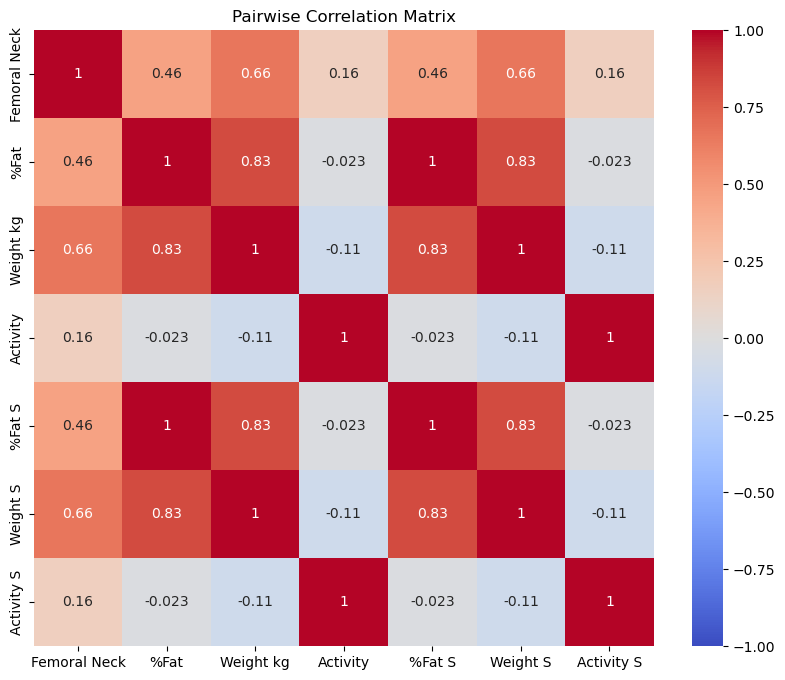

In [18]:
# Correlation heat map
correl_data = data[['Femoral Neck','%Fat','Weight kg','Activity' ,'%Fat S', 'Weight S','Activity S']]

# Compute the pairwise correlation matrix
corr_matrix = correl_data.corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Pairwise Correlation Matrix')
plt.show()
